In [2]:
import zipfile

zip_path = "/content/Cotton__Disease.zip"   # uploaded file
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")


Dataset extracted!


In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt

In [7]:
img_size = (128, 128) #  resizes the shape for uniformity of images
batch_size = 32

datagen = ImageDataGenerator(  #an helper tool from keras that helps load images and prepares it for neural network
    rescale=1./255,
)


train_data = datagen.flow_from_directory(
    "/content/dataset/Cotton Disease/train",
    target_size=(128, 128),
    batch_size=32,
    class_mode="categorical"
)

val_data = datagen.flow_from_directory(
    "/content/dataset/Cotton Disease/val",
    target_size=(128, 128),
    batch_size=32,
    class_mode="categorical", # tells the model i have more than one and I want one-hot labels
    shuffle=False # maintains the order that validation data is used forvalidation alone
)

#val_data.class_indices
#val_data.samples
#val_data.image_shape

test_data = datagen.flow_from_directory(
    "/content/dataset/Cotton Disease/test",
    target_size=(128, 128),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)




num_classes = train_data.num_classes
print("Classes:", train_data.class_indices)


Found 1951 images belonging to 4 classes.
Found 253 images belonging to 4 classes.
Found 106 images belonging to 4 classes.
Classes: {'diseased cotton leaf': 0, 'diseased cotton plant': 1, 'fresh cotton leaf': 2, 'fresh cotton plant': 3}


In [ ]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.25),          

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.25),          

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.25),          

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),           

    layers.Dense(num_classes, activation='softmax')
])



/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    epochs=100,
    batch_size=32,
    validation_data=val_data,
    callbacks=[early_stop]
)



/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.3904 - loss: 1.6349 - val_accuracy: 0.5375 - val_loss: 1.0808
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.5760 - loss: 0.9768 - val_accuracy: 0.6640 - val_loss: 0.8290
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.6737 - loss: 0.8385 - val_accuracy: 0.7628 - val_loss: 0.7015
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.7118 - loss: 0.7363 - val_accuracy: 0.7549 - val_loss: 0.6648
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.7590 - loss: 0.6028 - val_accuracy: 0.7787 - val_loss: 0.5886
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.7840 - loss: 0.5325 - val_accuracy: 0.8538 - val_loss: 0.4999
Epoch 7/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.8051 - loss: 0.5035 - val_accuracy: 0.8538 - val_loss: 0.4336
Epoch 8/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.8378 - loss: 0.4503 - val_accuracy: 0.8300 - v

In [ ]:
for i, acc in enumerate(history.history['accuracy']):
    print(f"Epoch {i+1}: stored training accuracy = {acc:.4f}")



Epoch 1: stored training accuracy = 0.4500
Epoch 2: stored training accuracy = 0.6212
Epoch 3: stored training accuracy = 0.6771
Epoch 4: stored training accuracy = 0.7294
Epoch 5: stored training accuracy = 0.7576
Epoch 6: stored training accuracy = 0.7801
Epoch 7: stored training accuracy = 0.7955
Epoch 8: stored training accuracy = 0.8401
Epoch 9: stored training accuracy = 0.8426
Epoch 10: stored training accuracy = 0.8596
Epoch 11: stored training accuracy = 0.8596
Epoch 12: stored training accuracy = 0.8795
Epoch 13: stored training accuracy = 0.8847
Epoch 14: stored training accuracy = 0.9072
Epoch 15: stored training accuracy = 0.9103
Epoch 16: stored training accuracy = 0.9011
Epoch 17: stored training accuracy = 0.9134
Epoch 18: stored training accuracy = 0.9139
Epoch 19: stored training accuracy = 0.9257


In [ ]:
val_losses = history.history['val_loss']
best_epoch = np.argmin(val_losses) + 1   # +1 because epochs are 1-indexed

train_acc = history.history['accuracy'][best_epoch - 1]
val_acc   = history.history['val_accuracy'][best_epoch - 1]
best_val_loss = val_losses[best_epoch - 1]

print(f"Best epoch: {best_epoch}")
print(f"Training accuracy: {train_acc:.4f}")
print(f"Validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")

Best epoch: 14
Training accuracy: 0.9072
Validation loss: 0.2570
Validation accuracy: 0.9051


In [ ]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 589ms/step - accuracy: 0.9544 - loss: 0.2396
Test Loss: 0.2415044605731964
Test Accuracy: 0.9433962106704712


In [ ]:
import numpy as np

predictions = model.predict(test_data)

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 572ms/step


In [ ]:
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_data.classes


In [ ]:
class_names = list(test_data.class_indices.keys())

for i in range(5):
    print("Predicted:", class_names[predicted_classes[i]],
          "| Actual:", class_names[true_classes[i]])


Predicted: diseased cotton leaf | Actual: diseased cotton leaf
Predicted: diseased cotton leaf | Actual: diseased cotton leaf
Predicted: diseased cotton leaf | Actual: diseased cotton leaf
Predicted: diseased cotton leaf | Actual: diseased cotton leaf
Predicted: diseased cotton leaf | Actual: diseased cotton leaf


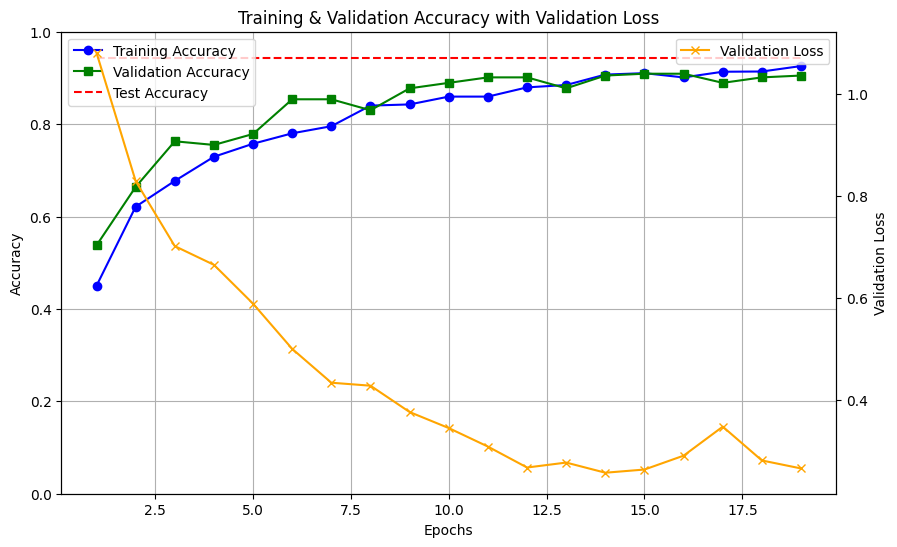

In [ ]:


#  Get metrics from history
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

# Number of epochs actually run
epochs_ran = len(train_acc)
epochs = range(1, epochs_ran + 1)

#  Create figure and twin y-axis
fig, ax1 = plt.subplots(figsize=(10,6))

# Accuracy lines on left y-axis
ax1.plot(epochs, train_acc, label='Training Accuracy', marker='o', color='blue')
ax1.plot(epochs, val_acc, label='Validation Accuracy', marker='s', color='green')
ax1.hlines(test_accuracy, xmin=1, xmax=epochs_ran, colors='red', linestyles='dashed', label='Test Accuracy')

ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.set_ylim(0, 1)
ax1.legend(loc='upper left')

# Loss line on right y-axis
ax2 = ax1.twinx()
ax2.plot(epochs, val_loss, label='Validation Loss', marker='x', color='orange')
ax2.set_ylabel('Validation Loss')
ax2.legend(loc='upper right')

# Title and grid
plt.title('Training & Validation Accuracy with Validation Loss')
ax1.grid(True)

plt.show()


Number of classes identified: 4
Model architecture defined and ready for prediction.
Loading test data...
Found 106 images belonging to 4 classes.
Searching for image #1 of class 'fresh cotton leaf'...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Found image! Explaining image with True Class: fresh cotton leaf
Generating LIME explanation...


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

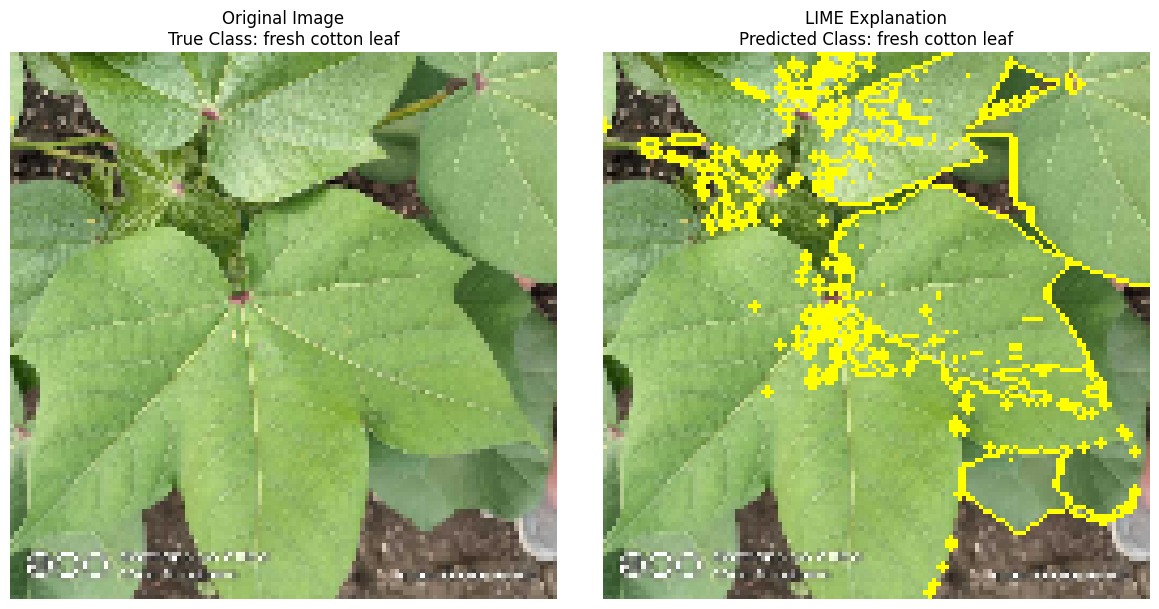

Explanation complete.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras import models, layers # Corrected import for models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from lime import lime_image
from skimage.segmentation import mark_boundaries
import os



# Assuming the basic model name.
MODEL_PATH = 'model_basic_cnn.h5'
TEST_DIR = r"/content/dataset/Cotton Disease/test"
IMG_SIZE = (128, 128) # Corrected to match the model's training input size
BATCH_SIZE = 32


# Available classes: diseased cotton leaf, diseased cotton plant, fresh cotton leaf, fresh cotton plant
TARGET_CLASS_NAME = 'fresh cotton leaf'
TARGET_INDEX = 1 # 0 for the 1st image, 1 for the 2nd


# Model Definition and Loading (Ensuring 'model' is defined)

# This section is added to ensure the 'model' object is defined if previous cells were not run
# or the kernel state was reset.

# First, try to get num_classes from the test_data (defined previously)
# If test_data is not available, we need a default or to re-run data loading
try:
    # Assuming test_data.class_indices is available from a previous cell's execution
    num_classes = len(test_data.class_indices)
except NameError:
    print("Warning: 'test_data' not found. Re-initializing a minimal generator to get class count.")
    # Fallback to re-create a temporary generator to get num_classes
    temp_datagen = ImageDataGenerator(rescale=1./255)
    temp_generator = temp_datagen.flow_from_directory(
        TEST_DIR,
        target_size=IMG_SIZE,
        batch_size=1, # only need one sample to get class count
        class_mode='categorical',
        shuffle=False
    )
    num_classes = temp_generator.num_classes
    del temp_datagen, temp_generator # Clean up temporary objects

print(f"Number of classes identified: {num_classes}")

# Re-define the model architecture as it was in cell pnbcJbzy7FEz
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation='softmax')
])

# It's important to compile the model as well, even if not re-training, for prediction purposes.
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# If a saved model exists, load its weights. Otherwise, it will use randomly initialized weights.
# This assumes model_basic_cnn.h5 might exist from a previous save operation not shown.
if os.path.exists(MODEL_PATH):
    try:
        # Load only weights if architecture is re-defined, or full model if architecture not re-defined
        model.load_weights(MODEL_PATH)
        print(f"Loaded weights from {MODEL_PATH}")
    except Exception as e:
        print(f"Warning: Could not load weights from {MODEL_PATH}: {e}")
        print("Model will use randomly initialized weights. For proper LIME, ensure model is trained and weights are loaded.")
else:
    print(f"Warning: {MODEL_PATH} not found. Model will use randomly initialized weights. For proper LIME, ensure model is trained and weights are loaded.")

print("Model architecture defined and ready for prediction.")


# Data Loading (For Visualization)

print("Loading test data...")
test_datagen_raw = ImageDataGenerator() # No preprocessing here, we want raw 0-255 for LIME visualization

test_generator_raw = test_datagen_raw.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # Deterministic selection
)


# Prediction Function (The Bridge)

def predict_fn(images):
    """
    LIME passes 'images' as a numpy array of shape (batch, h, w, c) with values 0-255.
    For a Basic CNN (trained with rescale=1./255), we typically just divide by 255.
    """
    images = np.array(images, dtype=np.float32)

    # Basic CNN Preprocessing: Rescale to [0, 1]
    # This is different from ResNet/EffNet specific preprocessing
    processed_images = images / 255.0

    return model.predict(processed_images)



# Find the Target Image

print(f"Searching for image #{TARGET_INDEX} of class '{TARGET_CLASS_NAME}'...")

label_map = (test_generator_raw.class_indices)
label_map_inv = {v: k for k, v in label_map.items()}

if TARGET_CLASS_NAME not in label_map:
    print(f"Error: Class '{TARGET_CLASS_NAME}' not found. Available classes: {list(label_map.keys())}")
    exit()

target_class_idx = label_map[TARGET_CLASS_NAME]

img_to_explain = None
true_label_idx = None
count = 0
found = False

test_generator_raw.reset()
max_batches = len(test_generator_raw)

for i in range(max_batches):
    batch_images, batch_labels = next(test_generator_raw)

    for j in range(len(batch_images)):
        current_label_idx = np.argmax(batch_labels[j])

        if current_label_idx == target_class_idx:
            if count == TARGET_INDEX:
                img_to_explain = batch_images[j]
                true_label_idx = current_label_idx
                found = True
                break
            count += 1
    if found:
        break

if not found:
    print(f"Error: Could not find image #{TARGET_INDEX} of class '{TARGET_CLASS_NAME}'.")
    exit()

print(f"Found image! Explaining image with True Class: {label_map_inv[true_label_idx]}")


# Run LIME

print("Generating LIME explanation...")
explainer = lime_image.LimeImageExplainer()

explanation = explainer.explain_instance(
    image=img_to_explain.astype('double'),
    classifier_fn=predict_fn,
    top_labels=5,
    hide_color=0,
    num_samples=1000
)

top_pred_class = explanation.top_labels[0]
top_pred_name = label_map_inv[top_pred_class]
print(f"Top Predicted Class: {top_pred_name}")

temp, mask = explanation.get_image_and_mask(
    top_pred_class,
    positive_only=True,
    num_features=5,
    hide_rest=False
)


# Visualize

plt.figure(figsize=(12, 6))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(img_to_explain.astype('uint8'))
plt.title(f"Original Image\nTrue Class: {label_map_inv[true_label_idx]}") # Shows Class Name
plt.axis('off')

# LIME Explanation
plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp.astype('uint8'), mask))
plt.title(f"LIME Explanation\nPredicted Class: {top_pred_name}") # Shows Class Name
plt.axis('off')

plt.tight_layout()
plt.show()

print("Explanation complete.")